# Survey of India land cover, 1914–15

Reproduces Table 1 and the 1914–15 classification of Sirsa (Figure 8a, Table 3) of Gerrits et al. (in review).

In [1]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib import patheffects as pe
from matplotlib.patches import Patch
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.plot import plotting_extent
from rasterio.transform import from_origin
from rasterio.warp import reproject

import soi_landcover as sl

## 1. Calibration (Table 1)

Reference polygons on five sheets. Labels: `cultivated` = pale wash (*Grass lands*), reported as grassland; `bare/other` = no areal colour.

In [2]:
polys = gpd.read_file("data/reference_polygons.gpkg")
pixels = np.load("data/reference_pixels.npz")
rgb, polygon_id = pixels["rgb"], pixels["polygon_id"]

print(f"{len(polys)} polygons, {len(rgb):,} labelled pixels")
polys.groupby(["paper_class", "sheet"]).size().unstack(fill_value=0)

51 polygons, 491,729 labelled pixels


sheet,44K/14,44O/02,44O/03,53C/09,53C/13
paper_class,,,,,
Built-up,3,2,1,4,0
Cropland,1,4,3,1,2
Grassland,2,3,2,2,2
Natural / vegetated,2,2,0,0,2
No areal colour,0,2,1,0,0
Water,0,2,2,2,4


Grid search over 1,280 rule sets by macro accuracy, leave-one-sheet-out.

In [3]:
truth = np.array([sl.NAME2CODE[d] for d in polys["description"]])[polygon_id]
sheet = polys["sheet"].to_numpy()[polygon_id]
h, s, v = sl.hsv(rgb.T)
combos = sl.all_rule_combinations()

idx = {c: i for i, c in enumerate(sl.CODES)}
cm = np.zeros((len(sl.CODES), len(sl.CODES)), int)   # rows reference, columns predicted
for held_out in sorted(set(sheet)):
    train, test = sheet != held_out, sheet == held_out
    rules, _ = sl.best_rules(sl.Pool(h[train], s[train], v[train], truth[train]), combos)
    pred = sl.classify_pixels(h[test], s[test], v[test], rules)
    for t in sl.CODES:
        for p in sl.CODES:
            cm[idx[t], idx[p]] += int(((truth[test] == t) & (pred == p)).sum())

label = {1: "Built-up", 2: "Water", 3: "Cropland", 5: "Grassland",
         4: "Natural / vegetated", 0: "No areal colour"}
names = [label[c] for c in sl.CODES]
table = pd.DataFrame(100 * cm / cm.sum(1, keepdims=True), index=names, columns=names)
table = table.round(1)
table.insert(0, "Pixels", cm.sum(1))
table["Producer's accuracy"] = (100 * cm.diagonal() / cm.sum(1)).round(1)
table["User's accuracy"] = (100 * cm.diagonal() / cm.sum(0)).round(1)

print(f"Macro accuracy {100 * (cm.diagonal() / cm.sum(1)).mean():.1f}%, "
      f"pixel accuracy {100 * cm.diagonal().sum() / cm.sum():.1f}%   "
      f"(Table 1: 72.6% and 86.2%)")
table

Macro accuracy 72.6%, pixel accuracy 86.2%   (Table 1: 72.6% and 86.2%)


,Pixels,Built-up,Water,Cropland,Grassland,Natural / vegetated,No areal colour,Producer's accuracy,User's accuracy
Built-up,19889,91.9,0.0,0.0,0.0,0.0,8.1,91.9,69.3
Water,39442,18.1,53.5,0.1,0.2,0.0,28.1,53.5,99.6
Cropland,277469,0.0,0.0,97.0,2.0,0.2,0.7,97.0,96.0
Grassland,102883,0.1,0.1,2.6,88.9,0.1,8.3,88.9,79.7
Natural / vegetated,22019,0.2,0.0,0.4,0.0,93.5,5.9,93.5,96.7
No areal colour,30027,2.3,0.0,28.1,58.7,0.0,10.8,10.8,11.7


Rules fitted on all five sheets:

In [4]:
chosen, _ = sl.best_rules(sl.Pool(h, s, v, truth), combos)
thresholds = [("cultivated", "sat_max", "grassland | cropland saturation split"),
              ("veg", "val_max", "vegetation value ceiling"),
              ("built", "sat_min", "built-up saturation floor"),
              ("water", "sat_min", "water saturation floor"),
              ("cultivated", "sat_min", "grassland saturation floor")]
pd.DataFrame([(d, chosen[c][k], sl.RULES[c][k]) for c, k, d in thresholds],
             columns=["threshold", "chosen here", "used in the paper"])

,threshold,chosen here,used in the paper
0,grassland | cropland saturation split,0.125,0.125
1,vegetation value ceiling,0.950,0.950
2,built-up saturation floor,0.160,0.160
3,water saturation floor,0.100,0.100
4,grassland saturation floor,0.040,0.040


## 2. Sirsa, 1914–15

Sheet excerpt from 44K/14, 44O/02 and 44O/03; band 4 is the on-sheet mask.

In [5]:
with rasterio.open("data/sirsa_soi_sample.tif") as src:
    sample = src.read()
    sample_transform = src.transform
inside = sample[3] > 0
native = sl.classify_map(sample[:3], inside)
print(f"classified {native.size:,} pixels, {100 * inside.mean():.1f}% on a map sheet")

classified 3,082,034 pixels, 99.9% on a map sheet


Reprojection to 4 m UTM 43N over the analysis extents (`sirsa_grids.json`). Reprojecting the excerpt alone differs on ~0.2% of pixels.

In [6]:
grids = json.load(open("data/sirsa_grids.json"))
ng, og = grids["native_grid"], grids["output_grid"]

full_native = np.full((ng["height"], ng["width"]), 255, "uint8")
r0, c0 = ng["sample_row_off"], ng["sample_col_off"]
full_native[r0:r0 + native.shape[0], c0:c0 + native.shape[1]] = native

out_transform = from_origin(og["west"], og["north"], og["res_m"], og["res_m"])
full_out = np.full((og["height"], og["width"]), 255, "uint8")
reproject(full_native, full_out,
          src_transform=from_origin(ng["west"], ng["north"], ng["res_deg"], ng["res_deg"]),
          src_crs=ng["crs"], dst_transform=out_transform, dst_crs=og["crs"],
          src_nodata=255, dst_nodata=255, resampling=Resampling.nearest)

with rasterio.open("data/sirsa_pipeline_harmonised.tif") as ref:
    published = ref.read(1)
    ref_transform = ref.transform
col = round((ref_transform.c - og["west"]) / og["res_m"])
row = round((og["north"] - ref_transform.f) / og["res_m"])
mine = sl.harmonise(full_out[row:row + published.shape[0], col:col + published.shape[1]])

print(f"identical to the raster used in the paper: {100 * (mine == published).mean():.4f}% "
      f"of {mine.size:,} pixels")

identical to the raster used in the paper: 100.0000% of 1,562,500 pixels


Built-up as share of observed ground per zone, site perimeter excluded.

In [7]:
rings = gpd.read_file("data/sirsa_zones.gpkg", layer="rings")
paper = {"0_1000": 17.683, "1000_2000": 7.395}   # data release; Table 3 rounds 0-1 km to 17.7

rows = []
for _, zone in rings.iterrows():
    m = rasterize([(zone.geometry, 1)], out_shape=mine.shape,
                  transform=ref_transform).astype(bool)
    built = (mine[m] == 1).sum() / np.isin(mine[m], sl.OBSERVED).sum()
    rows.append((f"{zone.ring_inner_m / 1000:g}-{zone.ring_outer_m / 1000:g} km",
                 round(100 * built, 3), paper[zone.ring_id]))
pd.DataFrame(rows, columns=["zone", "built-up % (this notebook)", "built-up % (paper)"])

,zone,built-up % (this notebook),built-up % (paper)
0,0-1 km,17.683,17.683
1,1-2 km,7.395,7.395


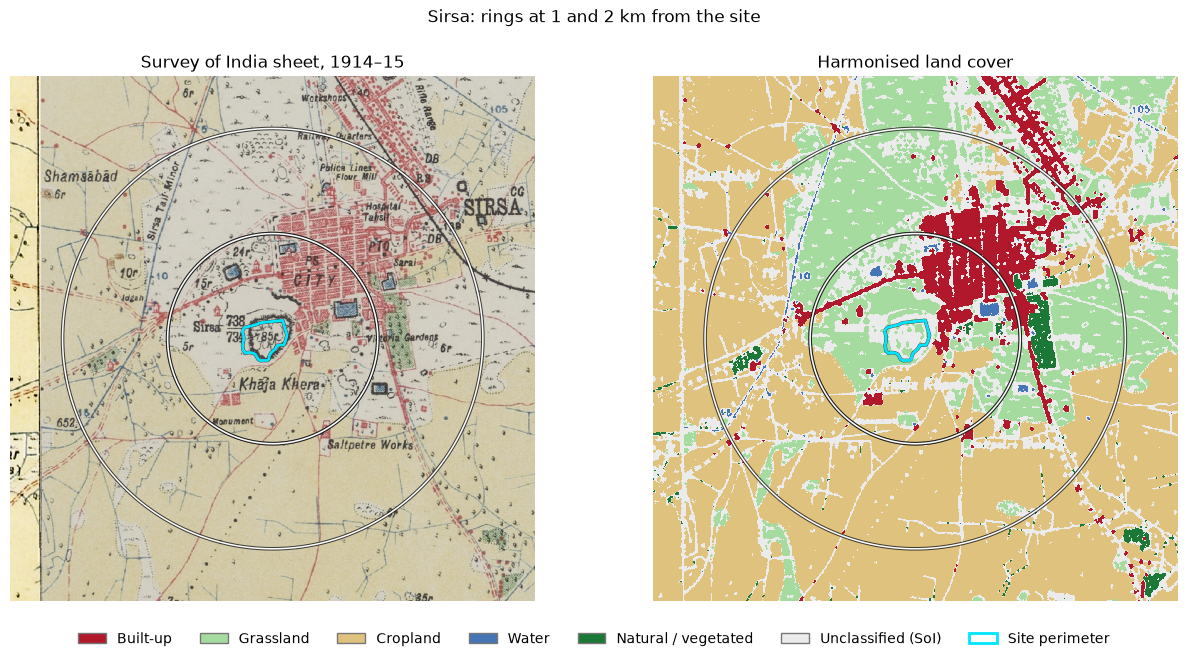

In [8]:
sheet_img = np.zeros((4,) + mine.shape, "uint8")
for b in range(4):
    reproject(sample[b], sheet_img[b], src_transform=sample_transform,
              src_crs="EPSG:4326", dst_transform=ref_transform, dst_crs=og["crs"],
              resampling=Resampling.nearest)
palette = np.zeros((256, 4), "uint8")
for k, c in sl.HARM_COLOURS.items():
    palette[k] = (*c, 0 if k == 255 else 255)

perimeter = gpd.read_file("data/sirsa_zones.gpkg", layer="site_perimeter")
extent = plotting_extent(mine, ref_transform)
halo = [pe.withStroke(linewidth=2.6, foreground="#1a1a1acc")]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
axes[0].imshow(np.moveaxis(sheet_img, 0, -1), extent=extent)
axes[1].imshow(palette[mine], extent=extent, interpolation="nearest")
for ax, title in zip(axes, ["Survey of India sheet, 1914–15", "Harmonised land cover"]):
    rings.boundary.plot(ax=ax, color="white", linewidth=1.1, path_effects=halo)
    perimeter.boundary.plot(ax=ax, color="#00e5ff", linewidth=2.0)
    ax.set_title(title)
    ax.set_axis_off()

present = [k for k in (1, 7, 2, 3, 4, 5, 6) if (mine == k).any()]
handles = [Patch(fc=np.array(sl.HARM_COLOURS[k]) / 255, ec="#777777",
                 label=sl.HARM_LABELS[k]) for k in present]
handles.append(Patch(fc="none", ec="#00e5ff", lw=2, label="Site perimeter"))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
fig.suptitle("Sirsa: rings at 1 and 2 km from the site", y=0.98)
fig.tight_layout(rect=(0, 0.06, 1, 0.95))